# Exercise 1: Embeddings and distances

Clustering aerial scenes with embeddings from a pre-trained vision transformer.

Two inputs, both from HuggingFace:

* **the images** - `blanchon/UC_Merced`, 2,100 aerial scenes in 21 classes
* **the embeddings** - `MustafaArikan/vit_embeddings_uc_merced_layers`, embedding vectors taken
  from 7 depths of a ViT (768 dims each)

## 1. Load the dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import hf_hub_download

DATA = "blanchon/UC_Merced"

ds = load_dataset(DATA, split="train")
class_names = ds.features["label"].names
labels = np.array(ds["label"])

print(f"{len(ds)} images, {len(class_names)} classes")
print(class_names)

README.md:   0%|          | 0.00/2.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  416MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2100 [00:00<?, ? examples/s]

2100 images, 21 classes
['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


## 2. Embeddings

In [2]:
order = np.asarray(sorted(range(len(ds)), key=lambda i: (class_names[labels[i]], i)))
y_all = labels[order] + 1                      # 1-based, as in the embeddings

rng = np.random.default_rng(0)
train_idx, test_idx = [], []
for label in range(1, len(class_names) + 1):
    idx = np.where(y_all == label)[0]
    rng.shuffle(idx)
    n_test = max(1, int(round(len(idx) * 0.2)))
    test_idx += list(idx[:n_test])
    train_idx += list(idx[n_test:])

train_idx, test_idx = np.asarray(train_idx), np.asarray(test_idx)

print(f"train {len(train_idx)} / test {len(test_idx)}")

train 1680 / test 420


## 3. Align the training images

Some of the 2,100 images are a few pixels off 256 x 256, so they are resized here;
`np.stack` would fail otherwise.

In [3]:
def to_rgb(row):
    im = row["image"].convert("RGB")
    if im.size != (256, 256):
        im = im.resize((256, 256))
    return np.asarray(im)

X_train_rgb = np.stack([to_rgb(ds[int(i)]) for i in order[train_idx]])
y_train = y_all[train_idx]

print(X_train_rgb.shape, X_train_rgb.dtype)
print(y_train.shape)

(1680, 256, 256, 3) uint8
(1680,)


## 4. Load the embeddings

Seven depths are available. Index `0` is the patch embedding, before any attention;
`12` is the output of the last block.

In [11]:
REPO = "MustafaArikan/vit_embeddings_uc_merced_layers"
path = hf_hub_download(REPO, "vit_embeddings_uc_merced_layers.npz", repo_type="dataset")
d = np.load(path)

LAYERS = [0, 1, 2, 3, 6, 9, 12]
E_train = {k: d[f"E_train_l{k}"] for k in LAYERS}
E_test = {k: d[f"E_test_l{k}"] for k in LAYERS}

print("layers:", LAYERS)
print("dims  :", {k: v.shape for k, v in E_train.items()})
print("rows match the images:", np.array_equal(y_train, d["y_train"]))

vit_embeddings_uc_merced_layers.npz: reconstructing file:   0%|          |  0.00B / 35.9MB            

vit_embeddings_uc_merced_layers.npz: downloading bytes:           |  0.00B            

layers: [0, 1, 2, 3, 6, 9, 12]
dims  : {0: (1680, 768), 1: (1680, 768), 2: (1680, 768), 3: (1680, 768), 6: (1680, 768), 9: (1680, 768), 12: (1680, 768)}
rows match the images: True


## 5. The 10 farthest neighbours of one image

Cosine similarity against every other training image, sorted ascending, take the first 10.
"Farthest" means the images the model considers least alike.

In [20]:
E.shape, E[q].shape,norms.shape, norms[q]

((1680, 768), (768,), (1680,), np.float32(49.970867))

In [36]:
np.where(others)[0]

array([   0,    1,    2, ..., 1677, 1678, 1679], shape=(1679,))

In [33]:
np.where(others)[0][np.argsort(sims[others])][:10]

array([ 59,  19,  45,   6,  68, 417, 407, 448,  36, 457])

layer 3 | query: image 144  (airplane)

   1. image    59  agricultural     +0.872
   2. image    19  agricultural     +0.880
   3. image    45  agricultural     +0.887
   4. image     6  agricultural     +0.891
   5. image    68  agricultural     +0.907
   6. image   417  chaparral        +0.908
   7. image   407  chaparral        +0.908
   8. image   448  chaparral        +0.908
   9. image    36  agricultural     +0.909
  10. image   457  chaparral        +0.910


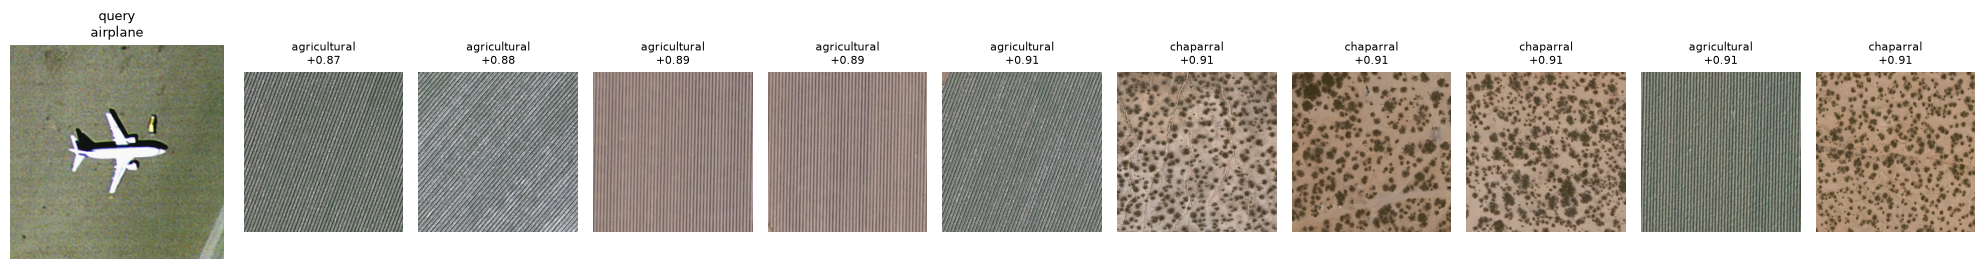

In [12]:
LAYER = 3                 # 0 = patch embeddings, 12 = last block
q = 144                   # query image index

E = E_train[LAYER]

norms = np.linalg.norm(E, axis=1)
sims = (E @ E[q]) / (norms * norms[q])

others = np.arange(len(E)) != q
farthest = np.where(others)[0][np.argsort(sims[others])][:10]

query_class = class_names[y_train[q] - 1]
print(f"layer {LAYER} | query: image {q}  ({query_class})\n")

for rank, j in enumerate(farthest, 1):
    print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {sims[j]:+.3f}")

fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                         gridspec_kw={"width_ratios": [1.4] + [1] * 10})

axes[0].imshow(X_train_rgb[q])
axes[0].set_title(f"query\n{query_class}", fontsize=9)
axes[0].axis("off")

for ax, j in zip(axes[1:], farthest):
    ax.imshow(X_train_rgb[j])
    ax.set_title(f"{class_names[y_train[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. TODO: the 10 nearest neighbours

Same computation, sorted the other way; take the first 10.

Then compare with the grid above:

* do the nearest neighbours share the query's class?
* how much more alike are they than the farthest ones?

   1. image    86  airplane         +0.990
   2. image    87  airplane         +0.988
   3. image    89  airplane         +0.986
   4. image   141  airplane         +0.984
   5. image   155  airplane         +0.983
   6. image   131  airplane         +0.982
   7. image   106  airplane         +0.982
   8. image   113  airplane         +0.982
   9. image   134  airplane         +0.982
  10. image   103  airplane         +0.981


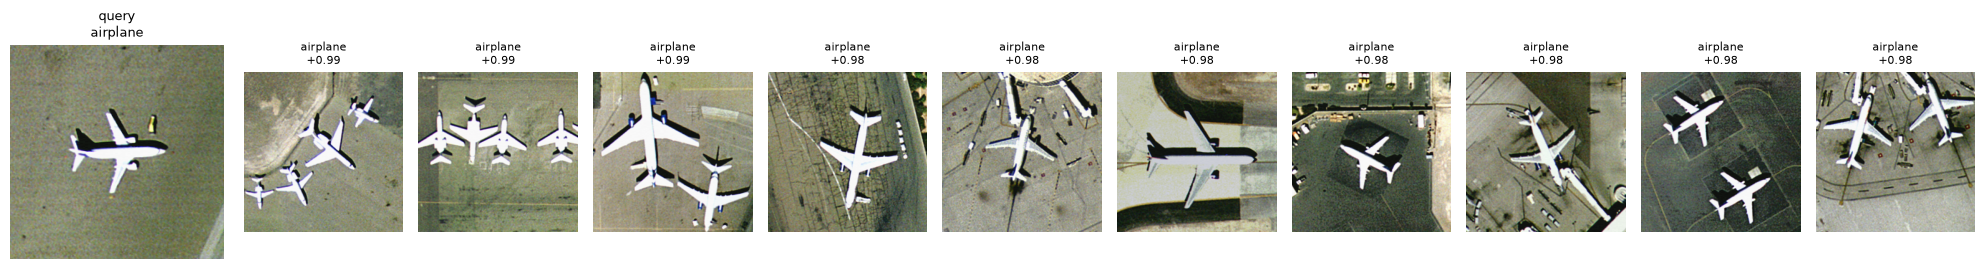

In [40]:
# TODO: top 10 nearest

nearest  = np.where(others)[0][np.argsort(sims[others])][::-1][:10]
for rank, j in enumerate(nearest, 1):
    print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {sims[j]:+.3f}")

fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                         gridspec_kw={"width_ratios": [1.4] + [1] * 10})

axes[0].imshow(X_train_rgb[q])
axes[0].set_title(f"query\n{query_class}", fontsize=9)
axes[0].axis("off")

for ax, j in zip(axes[1:], nearest):
    ax.imshow(X_train_rgb[j])
    ax.set_title(f"{class_names[y_train[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 7. TODO: the same, for another layer

Repeat the 10 nearest for a different depth: try `LAYER = 1`, `6` and `12`.

Which depth returns neighbours that actually share the class?

   1. image   774  golfcourse       +0.999
   2. image   195  baseballdiamond  +0.999
   3. image   217  baseballdiamond  +0.999
   4. image   181  baseballdiamond  +0.999
   5. image   239  baseballdiamond  +0.999
   6. image   779  golfcourse       +0.999
   7. image   208  baseballdiamond  +0.999
   8. image   743  golfcourse       +0.999
   9. image   236  baseballdiamond  +0.999
  10. image   755  golfcourse       +0.999


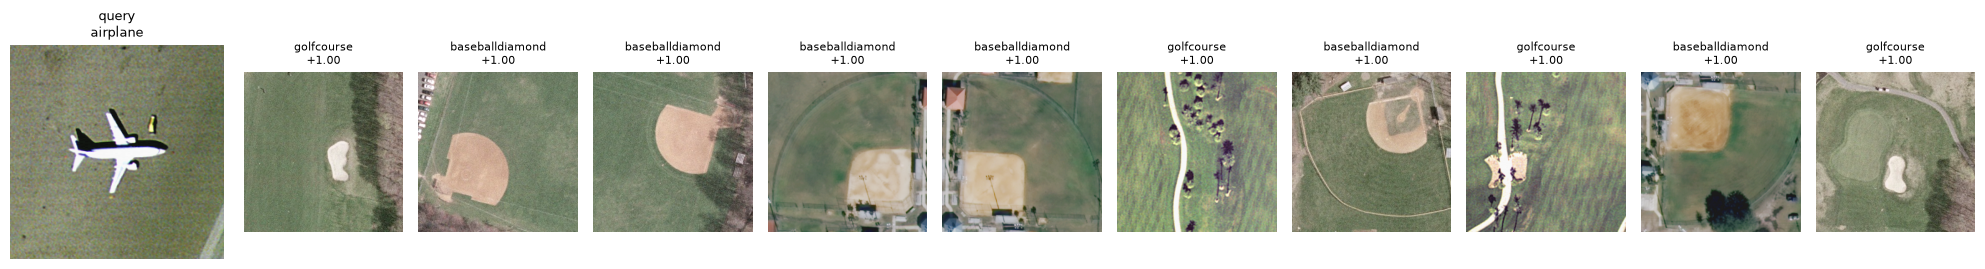

In [41]:
# TODO: top 10 nearest, another layer
LAYER = 1                 # 0 = patch embeddings, 12 = last block
q = 144                   # query image index

E = E_train[LAYER]

norms = np.linalg.norm(E, axis=1)
sims = (E @ E[q]) / (norms * norms[q])

others = np.arange(len(E)) != q
nearest  = np.where(others)[0][np.argsort(sims[others])][::-1][:10]
for rank, j in enumerate(nearest, 1):
    print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {sims[j]:+.3f}")

fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                         gridspec_kw={"width_ratios": [1.4] + [1] * 10})

axes[0].imshow(X_train_rgb[q])
axes[0].set_title(f"query\n{query_class}", fontsize=9)
axes[0].axis("off")

for ax, j in zip(axes[1:], nearest):
    ax.imshow(X_train_rgb[j])
    ax.set_title(f"{class_names[y_train[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

   1. image    86  airplane         +0.972
   2. image    89  airplane         +0.949
   3. image   141  airplane         +0.949
   4. image   155  airplane         +0.941
   5. image    83  airplane         +0.940
   6. image   103  airplane         +0.939
   7. image    98  airplane         +0.939
   8. image    87  airplane         +0.938
   9. image   133  airplane         +0.936
  10. image   152  airplane         +0.934


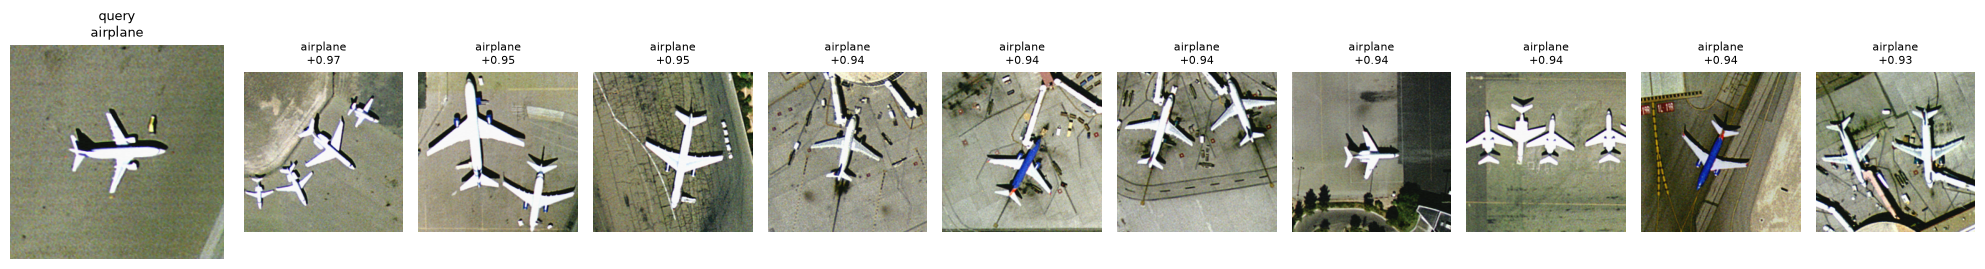

In [42]:
# TODO: top 10 nearest, another layer
LAYER = 6                 # 0 = patch embeddings, 12 = last block
q = 144                   # query image index

E = E_train[LAYER]

norms = np.linalg.norm(E, axis=1)
sims = (E @ E[q]) / (norms * norms[q])

others = np.arange(len(E)) != q
nearest  = np.where(others)[0][np.argsort(sims[others])][::-1][:10]
for rank, j in enumerate(nearest, 1):
    print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {sims[j]:+.3f}")

fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                         gridspec_kw={"width_ratios": [1.4] + [1] * 10})

axes[0].imshow(X_train_rgb[q])
axes[0].set_title(f"query\n{query_class}", fontsize=9)
axes[0].axis("off")

for ax, j in zip(axes[1:], nearest):
    ax.imshow(X_train_rgb[j])
    ax.set_title(f"{class_names[y_train[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

   1. image   158  airplane         +0.744
   2. image   145  airplane         +0.739
   3. image   147  airplane         +0.739
   4. image   120  airplane         +0.732
   5. image    98  airplane         +0.726
   6. image   108  airplane         +0.710
   7. image   150  airplane         +0.689
   8. image    90  airplane         +0.688
   9. image   101  airplane         +0.688
  10. image   131  airplane         +0.678


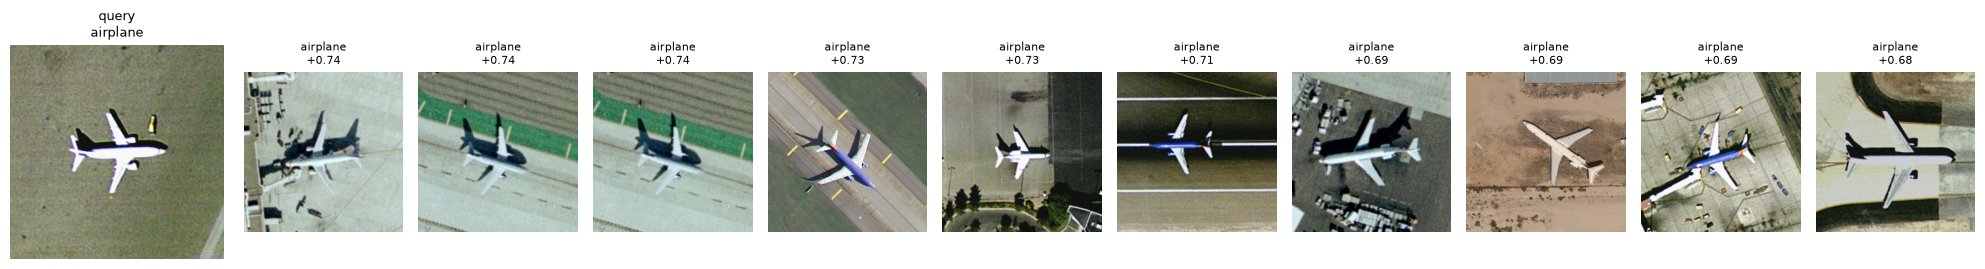

In [43]:
# TODO: top 10 nearest, another layer
LAYER = 12                # 0 = patch embeddings, 12 = last block
q = 144                   # query image index

E = E_train[LAYER]

norms = np.linalg.norm(E, axis=1)
sims = (E @ E[q]) / (norms * norms[q])

others = np.arange(len(E)) != q
nearest  = np.where(others)[0][np.argsort(sims[others])][::-1][:10]
for rank, j in enumerate(nearest, 1):
    print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {sims[j]:+.3f}")

fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                         gridspec_kw={"width_ratios": [1.4] + [1] * 10})

axes[0].imshow(X_train_rgb[q])
axes[0].set_title(f"query\n{query_class}", fontsize=9)
axes[0].axis("off")

for ax, j in zip(axes[1:], nearest):
    ax.imshow(X_train_rgb[j])
    ax.set_title(f"{class_names[y_train[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. TODO: another similarity measure

Cosine compares direction only and ignores magnitude. What else could you use to compare
two 768-dimensional vectors?

Find one alternative and show its 10 nearest for the same image:

e.g.
* Manhattan (L1), or correlation distance, does the ranking change?

Say in a sentence what each one assumes about the vectors.

layer 3 | query: image 144  (airplane)  | L1

   1. image    86  airplane         150.4
   2. image    87  airplane         168.4
   3. image    89  airplane         178.9
   4. image   155  airplane         192.3
   5. image   141  airplane         192.5
   6. image   113  airplane         200.6
   7. image   106  airplane         202.4
   8. image   131  airplane         202.8
   9. image   134  airplane         206.1
  10. image   103  airplane         207.5


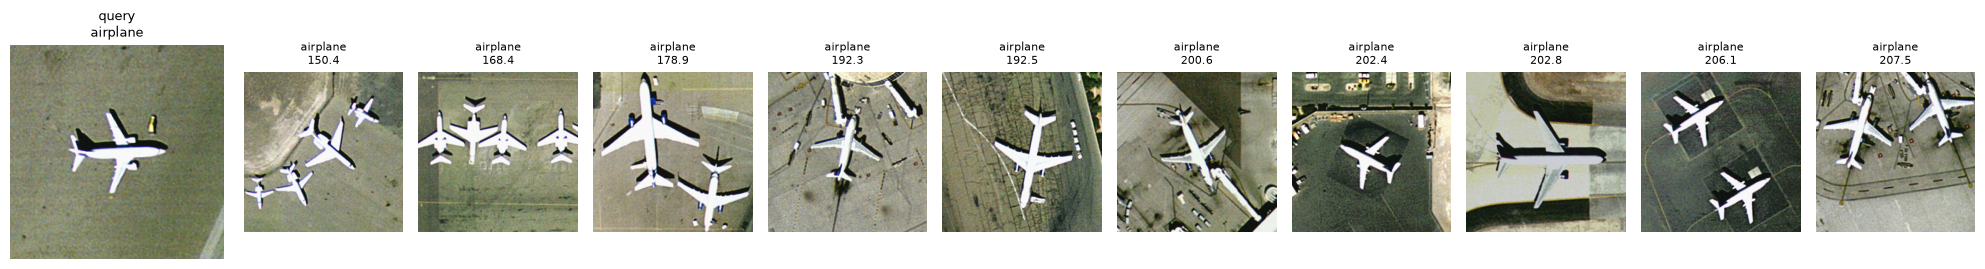

In [ ]:
LAYER = 3
q = 144
E = E_train[LAYER]                

query_class = class_names[y_train[q] - 1]

dists = np.abs(E - E[q]).sum(axis=1)
d = dists.copy()
d[q] = np.inf
nearest = np.argsort(d)[:10]

print(f"layer {LAYER} | query: image {q}  ({query_class})  | L1\n")
for rank, j in enumerate(nearest, 1):
    print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {dists[j]:.1f}")

fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                         gridspec_kw={"width_ratios": [1.4] + [1] * 10})

axes[0].imshow(X_train_rgb[q])
axes[0].set_title(f"query\n{query_class}", fontsize=9)
axes[0].axis("off")

for ax, j in zip(axes[1:], nearest):
    ax.imshow(X_train_rgb[j])
    ax.set_title(f"{class_names[y_train[j] - 1]}\n{dists[j]:.1f}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()
# Cosine: only the direction matters, vector length is ignored.
# L1: absolute values matter, every coordinate contributes independently and equally.